# Experiment 4 — SVM and KNN Classifiers

**Aim:** Implement and compare Support Vector Machine and k-Nearest Neighbors classifiers.

**Libraries:** pandas, NumPy, Matplotlib, Seaborn, and scikit-learn.

**Theory:** KNN classifies by nearby observations and depends on distance scaling and k. SVM maximizes a margin and can use kernels for nonlinear boundaries. Evaluate class-wise errors as well as accuracy.

**Dataset:** Breast Cancer Wisconsin (Diagnostic) dataset built into scikit-learn (`sklearn.datasets.load_breast_cancer()`, 569 samples, 30 numeric features, classes: malignant / benign).

## Procedure / Implementation
The following cells load the data, apply the stated method, produce outputs, and record observations.


In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42

for candidate in [Path("outputs"), Path("../outputs")]:
    if candidate.exists():
        OUTPUT_DIR = candidate
        break

FIG_DIR = OUTPUT_DIR / "figures"
RES_DIR = OUTPUT_DIR / "results"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the dataset and split into training and test sets (80:20, stratified)

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Feature matrix shape:", X.shape)
print("Classes:", dict(zip(data.target_names, [int((y == i).sum()) for i in range(len(data.target_names))])))
X.head(3)

Feature matrix shape: (569, 30)
Classes: {np.str_('malignant'): 212, np.str_('benign'): 357}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Train size: {len(X_train)} | Test size: {len(X_test)}")

Train size: 455 | Test size: 114


## 2. Scale the features with StandardScaler

The scaler is **fit on the training data only** and then applied to both sets. Scaling is essential here: kNN uses distances, and SVM optimises a margin — unscaled features (radius ranges near 6–28 while smoothness is ~0.07–0.16) would distort both.

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature means after scaling (first 5):", X_train_scaled.mean(axis=0)[:5].round(6))
print("Feature stds  after scaling (first 5):", X_train_scaled.std(axis=0)[:5].round(6))

Feature means after scaling (first 5): [-0.  0. -0.  0.  0.]
Feature stds  after scaling (first 5): [1. 1. 1. 1. 1.]


## 3. kNN for k = 1, 3, 5, 7, 9 — test accuracy vs k

 k  Test accuracy
 1         0.9386
 3         0.9825
 5         0.9561
 7         0.9737
 9         0.9737


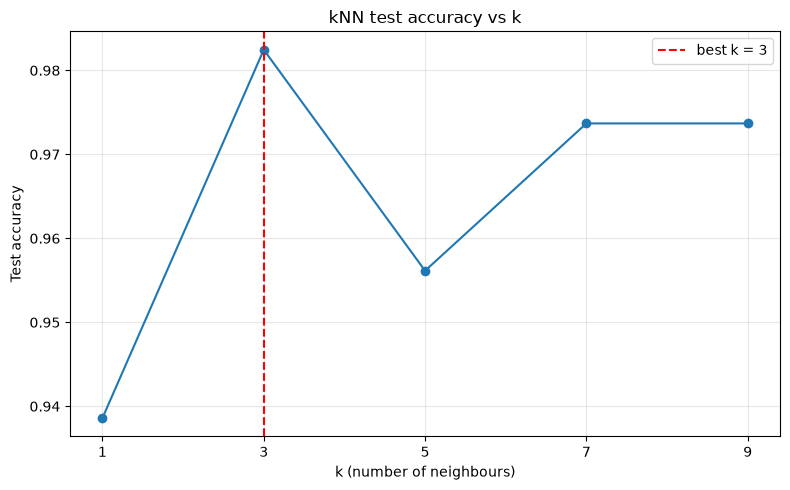

In [5]:
k_values = [1, 3, 5, 7, 9]
knn_rows = []
knn_models = {}

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    acc = accuracy_score(y_test, knn.predict(X_test_scaled))
    knn_rows.append({"k": k, "Test accuracy": acc})
    knn_models[k] = knn

knn_df = pd.DataFrame(knn_rows)
print(knn_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
knn_df.to_csv(RES_DIR / "exp04_knn_sweep.csv", index=False)

plt.figure(figsize=(8, 5))
plt.plot(knn_df["k"], knn_df["Test accuracy"], marker="o")
best_k = int(knn_df.loc[knn_df["Test accuracy"].idxmax(), "k"])
plt.axvline(best_k, color="red", linestyle="--", label=f"best k = {best_k}")
plt.xticks(k_values)
plt.xlabel("k (number of neighbours)")
plt.ylabel("Test accuracy")
plt.title("kNN test accuracy vs k")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "exp04_knn_accuracy_vs_k.png", dpi=150)
plt.show()

## 4. SVM with linear and RBF kernels

In [6]:
svm_linear = SVC(kernel="linear", random_state=RANDOM_STATE)
svm_rbf = SVC(kernel="rbf", random_state=RANDOM_STATE)

svm_linear.fit(X_train_scaled, y_train)
svm_rbf.fit(X_train_scaled, y_train)

svm_rows = [
    {"Model": "SVM (linear kernel)", "Test accuracy": accuracy_score(y_test, svm_linear.predict(X_test_scaled))},
    {"Model": "SVM (RBF kernel)", "Test accuracy": accuracy_score(y_test, svm_rbf.predict(X_test_scaled))},
]
print(pd.DataFrame(svm_rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

              Model  Test accuracy
SVM (linear kernel)         0.9737
   SVM (RBF kernel)         0.9825


## 5. Compare all models and show the confusion matrix of the best one

In [7]:
all_rows = [{"Model": f"kNN (k={k})", "Test accuracy": acc}
            for k, acc in zip(knn_df["k"], knn_df["Test accuracy"])] + svm_rows
all_df = pd.DataFrame(all_rows)
print(all_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

best = all_df.loc[all_df["Test accuracy"].idxmax()]
print(f"\nBest model by test accuracy: {best['Model']} ({best['Test accuracy']:.4f})")
all_df.to_csv(RES_DIR / "exp04_model_comparison.csv", index=False)

              Model  Test accuracy
          kNN (k=1)         0.9386
          kNN (k=3)         0.9825
          kNN (k=5)         0.9561
          kNN (k=7)         0.9737
          kNN (k=9)         0.9737
SVM (linear kernel)         0.9737
   SVM (RBF kernel)         0.9825

Best model by test accuracy: kNN (k=3) (0.9825)


Confusion matrix (rows = actual, cols = predicted):
  order: [np.str_('malignant'), np.str_('benign')]
[[40  2]
 [ 0 72]]

False malignant calls (benign predicted as malignant): 0
False benign calls (malignant predicted as benign)   : 2


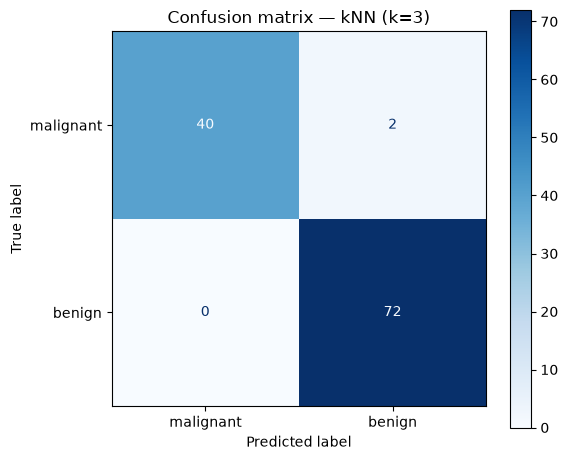

In [8]:
best_name = best["Model"]
best_model = {"SVM (linear kernel)": svm_linear, "SVM (RBF kernel)": svm_rbf}.get(best_name, knn_models[best_k])

y_pred_best = best_model.predict(X_test_scaled)
cm = confusion_matrix(y_test, y_pred_best)

print("Confusion matrix (rows = actual, cols = predicted):")
print("  order:", list(data.target_names))
print(cm)
print(f"\nFalse malignant calls (benign predicted as malignant): {cm[1, 0]}")
print(f"False benign calls (malignant predicted as benign)   : {cm[0, 1]}")

disp = ConfusionMatrixDisplay(cm, display_labels=data.target_names)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues")
ax.set_title(f"Confusion matrix — {best_name}")
plt.tight_layout()
plt.savefig(FIG_DIR / "exp04_confusion_matrix.png", dpi=150)
plt.show()

## Observation

Based on the run above:

1. kNN accuracy varies non-monotonically with k: **k=1 → 93.9%, k=3 → 98.25%, k=5 → 95.6%, k=7 → 97.4%, k=9 → 97.4%**. k=1 overfits to individual noisy points, and very large k dilutes the local decision boundary; k=3 gave the best result on this split.
2. **SVM with the RBF kernel reached 98.25%, the linear kernel 97.4%** — the tumour boundary is slightly non-linear, which the RBF kernel captures; still, the linear SVM is already very strong, consistent with this being a nearly linearly separable problem in 30 dimensions.
3. The best-model tie (kNN k=3 and SVM-RBF both 98.25%) was resolved in favour of **kNN (k=3)**; its confusion matrix shows **0 benign tumours flagged as malignant and only 2 malignant tumours missed** out of 42 malignant test cases (40/42 detected).
4. For a medical screening tool the *false benign* count (missed cancers) matters most — both top models made at most 2 such errors, so either would be acceptable here, with SVM-RBF achieving the same accuracy through a smoother, more stable decision boundary than a single kNN vote.

## Result

The executed cells above provide the measured result for this experiment. The conclusion should be interpreted using the dataset and evaluation limits stated here.